# 3. EDA (Exploratory Data Analysis)


In [1]:
import matplotlib.pyplot as plt # visualization
import numpy as np # numerical calcu
import pandas as pd # table operations
import seaborn as sns # rich visualization with mathplit
import warnings # avoid warnings
from scipy.stats import norm # statistical data
warnings.filterwarnings("ignore")

Input: `usedcars_stage2_cleaned.csv` from the preceding stage.

In [2]:
df = pd.read_csv('usedcars_stage2_cleaned.csv')
df.head()

,Name,Location,Manufacturing_Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price
0,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67,1582.0,126.20,5,12.50
1,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,13.00,1199.0,88.70,5,4.50
2,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77,1248.0,88.76,7,6.00
3,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968.0,140.80,5,17.74
4,Nissan Micra Diesel XV,Jaipur,2013,86999,Diesel,Manual,First,23.08,1461.0,63.10,5,3.50


# Univariative Analysis

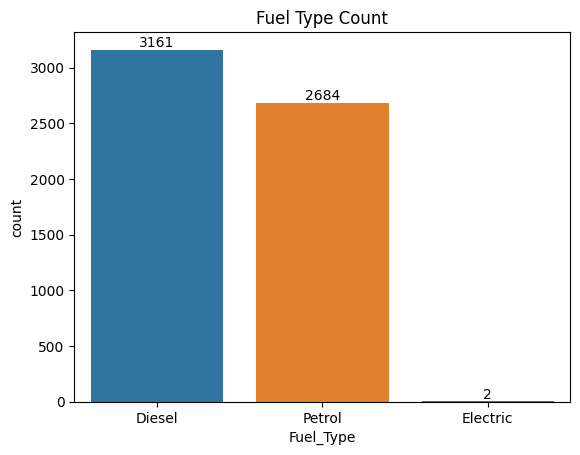

In [3]:
ax = sns.countplot(data=df, x='Fuel_Type',hue='Fuel_Type', order=df['Fuel_Type'].value_counts().index)
for container in ax.containers:
    ax.bar_label(container)
plt.title('Fuel Type Count')
plt.show()

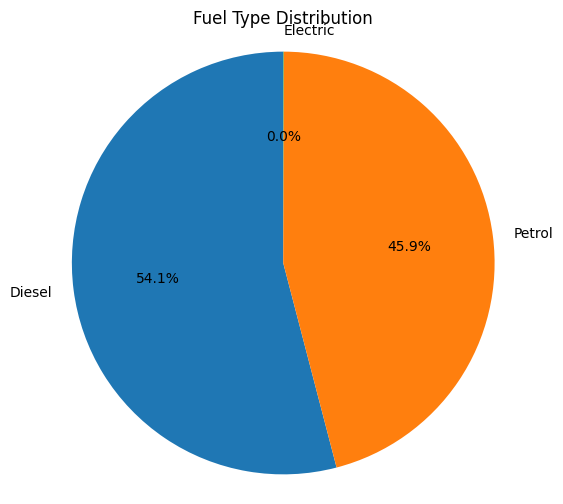

In [4]:
counts = df['Fuel_Type'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Fuel Type Distribution')
plt.axis('equal')    # keeps the pie circular
plt.show()

Inference:The Dataset is dominated with Diesel Cars and Petrol Cars (Imbalanced)

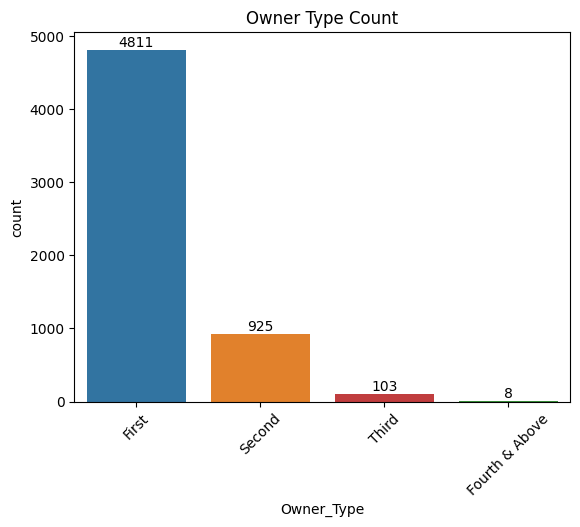

In [5]:
ax = sns.countplot(data=df,hue='Owner_Type', x='Owner_Type', order=df['Owner_Type'].value_counts().index)
for container in ax.containers:
    ax.bar_label(container)
plt.xticks(rotation=45)
plt.title('Owner Type Count')
plt.show()

Inference:The Dataset is dominated with First Owner Type (Imbalanced)

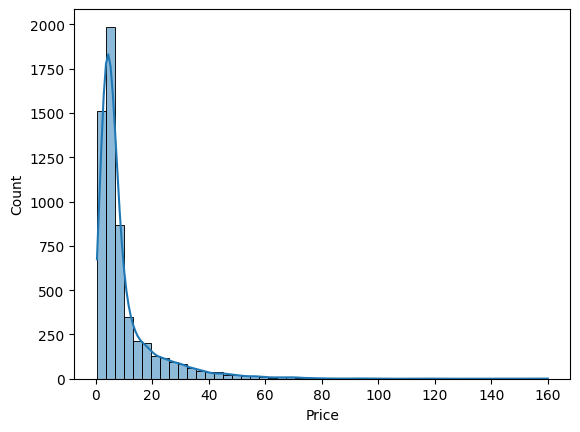

In [6]:
sns.histplot(df['Price'], bins=50, kde=True)
plt.show()

Inference:
1) The distribution is right-skewed
2) Most cars in the dataset are less expensive (budget friendly)
3) Exteme price is rare

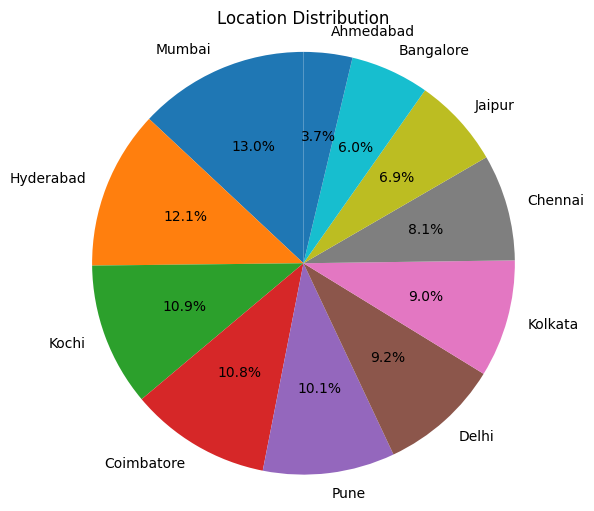

In [7]:
counts = df['Location'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Location Distribution')
plt.axis('equal')    # keeps the pie circular
plt.show()

Inference:
1) The cars in the dataset are faily even spread across the location
2) Most cars come from Mumbai,Hyderabad
3) Least cars come from Jaipur and Bangalore

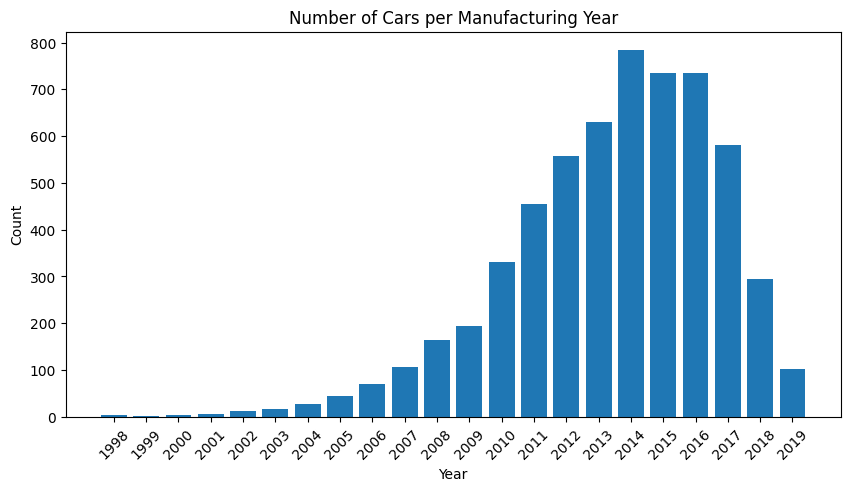

In [8]:
counts = df['Manufacturing_Year'].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.bar(counts.index.astype(str), counts.values)
plt.xlabel('Year')
plt.ylabel('Count')
plt.title('Number of Cars per Manufacturing Year')
plt.xticks(rotation=45)
plt.show()

Inference:
1) The graph is left skewed
2) The dataset has more records of years 2013 to 2017

# Bivariative Analysis

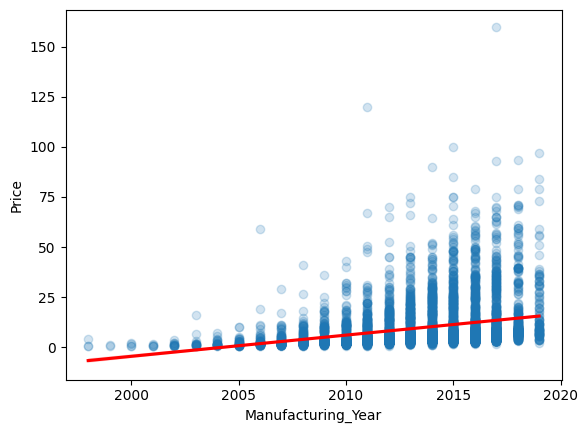

In [9]:
# regression plot : scatter plot + best fit line
sns.regplot(data=df, x='Manufacturing_Year', y='Price', scatter_kws={'alpha': 0.2}, line_kws={'color': 'red'})
plt.show()

Inference: The price increases gradually with respect to how recently the car is manufactured

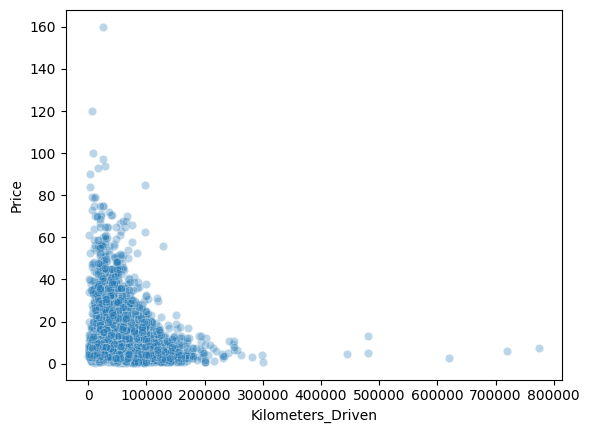

In [10]:
sns.scatterplot(data=df, x='Kilometers_Driven', y='Price', alpha=0.3)
plt.show()

Inference:
1) Price tends to fall as kilometers driven rise
2) Most cars are driven less than 20,000 kilometers
3) The most prices are between 40 to 20 lakhs

In [11]:
brand = df['Name'].str.split().str[0]
top = brand.value_counts().head(12).index
order = df[brand.isin(top)].groupby(brand)['Price'].median().sort_values().index

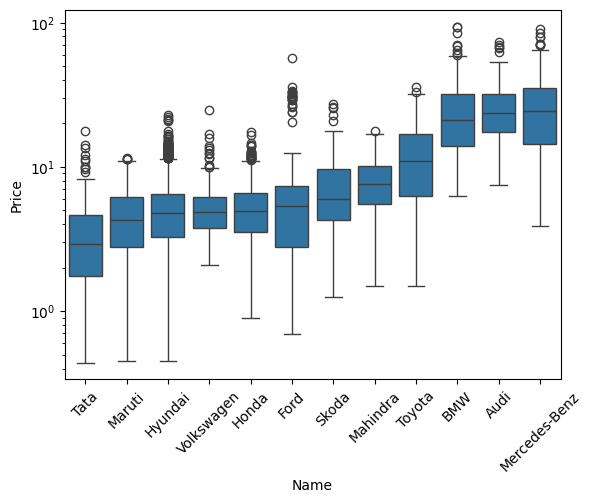

In [12]:
sns.boxplot(data=df[brand.isin(top)], x=brand[brand.isin(top)], y='Price', order=order)
plt.xticks(rotation=45)
plt.yscale('log')
plt.show()

Inference:
1) The mean costliest cars are from BMW,Audi,Mercedes-Benz
2) The mean least costliest cars are from Tata,Maruti,Hyundai

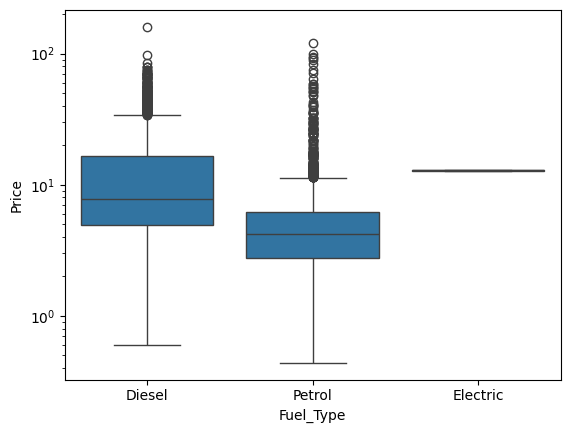

In [13]:
sns.boxplot(data=df, x='Fuel_Type', y='Price')
plt.yscale('log')
plt.show()

Inference:
1) The Mean costliest car is Electric Fuel Type cars
2) The Mean least costliest car is Petrol Fuel Type cars

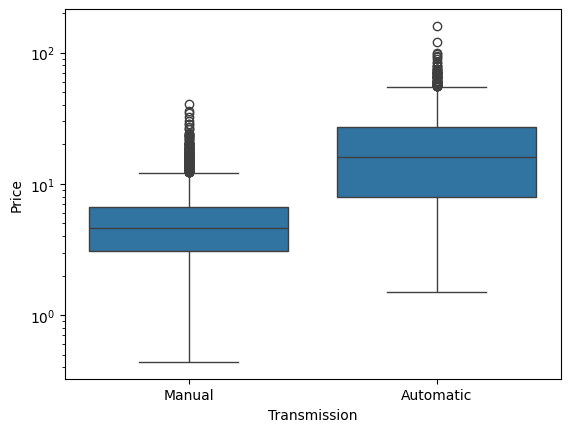

In [14]:
sns.boxplot(data=df, x='Transmission', y='Price')
plt.yscale('log')
plt.show()


Inference:The Mean costliest car is Automatic Transmission

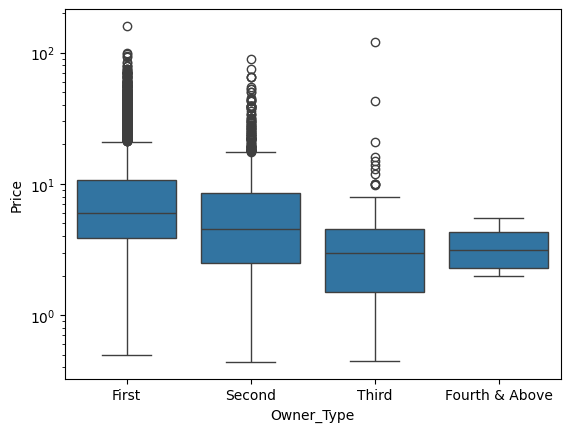

In [15]:
order = ['First', 'Second', 'Third', 'Fourth & Above']
sns.boxplot(data=df, x='Owner_Type', y='Price', order=order)
plt.yscale('log')
plt.show()

Inference: The mean price decrases with number of previous owners (except for Fourth & Above has a slight deviation)

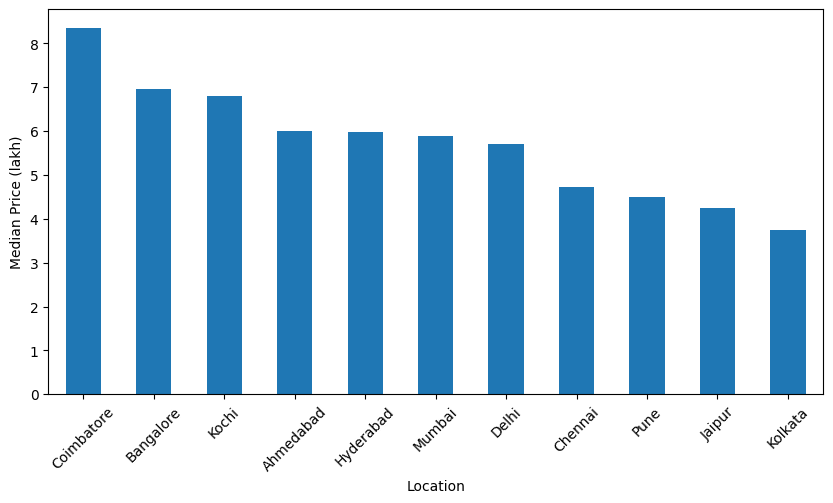

In [16]:
med = df.groupby('Location')['Price'].median().sort_values(ascending=False)
med.plot.bar(figsize=(10, 5))
plt.ylabel('Median Price (lakh)')
plt.xticks(rotation=45)
plt.show()

Inference:
1) Median Price for cars is higher in Coimbatore,Banflore,Kochi
2) Median Price for cars is lower in Pune,Jaipur,Kolkata

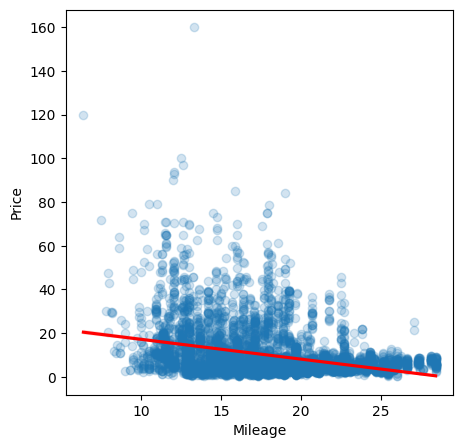

In [17]:
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
sns.regplot(data=df, x='Mileage', y='Price', scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})
plt.show()

Inference:Price decreases with Mileage of Car

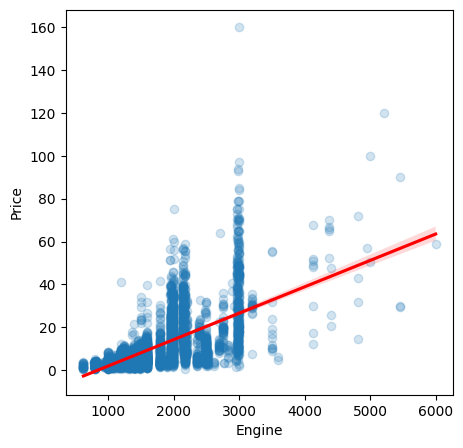

In [18]:
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
sns.regplot(data=df, x='Engine', y='Price', scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})
plt.show()

Inference:Price increases with Engine Size

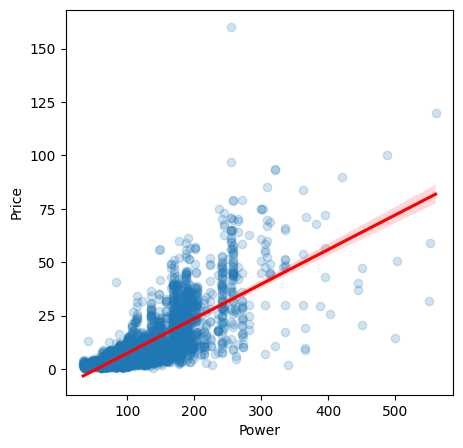

In [19]:
fig, axes = plt.subplots(1, 1, figsize=(5, 5))
sns.regplot(data=df, x='Power', y='Price', scatter_kws={'alpha': 0.2},line_kws={'color': 'red'})
plt.show()

Inference:Price increases with Power of Car

## Export for the next stage

Run this notebook after its input stage.

In [20]:
df.to_csv('usedcars_stage3_eda.csv', index=False)
print('Exported usedcars_stage3_eda.csv')

Exported usedcars_stage3_eda.csv
